# Biharmonic equation

This tutorial follows the biharmonic demo of
[DOLFINx](https://docs.fenicsproject.org/dolfinx/main/python/demos.html), written in
the Firedrake style.
We solve the simply supported plate problem

$$ \Delta^2 u = f \ \text{in } \Omega = (0,1)^2, \qquad u = 0, \ \Delta u = 0 \ \text{on } \partial\Omega , $$

with continuous piecewise quadratics.  Such functions are not in $H^2$, so the weak form
$\int \Delta u\,\Delta v\,dx$ is not meaningful on its own.  The $C^0$ interior penalty method
adds the missing terms on the interior facets: with the jump of the normal derivative
$[\![\nabla u]\!]= \nabla u^+\cdot n^+ + \nabla u^-\cdot n^-$ it reads

$$
\int_\Omega \Delta u\,\Delta v\,dx
- \int_{\mathcal F_i} \{\Delta u\}[\![\nabla v]\!] + [\![\nabla u]\!]\{\Delta v\}\,dS
+ \int_{\mathcal F_i} \frac{\alpha}{\{h\}}[\![\nabla u]\!][\![\nabla v]\!]\,dS
= \int_\Omega f v\,dx .
$$

The condition $u=0$ is essential and $\Delta u=0$ is natural, so only a standard
`DirichletBC` is needed.  The exact solution is $u_e=\sin(\pi x)\sin(\pi y)$ with
$f = 4\pi^4 u_e$.

## Variational form

The expression `div(grad(u))` is evaluated element by element, and `jump(grad(u), n)` is
the scalar jump of the normal derivative.

In [1]:
from ngsufl import *
import numpy as np

def solve_biharmonic(n, alpha=8.0, degree=2):
    mesh = UnitSquareMesh(n, n)
    V = FunctionSpace(mesh, "CG", degree)
    u, v = TrialFunction(V), TestFunction(V)
    x = SpatialCoordinate(mesh)
    nrm, h = FacetNormal(mesh), CellDiameter(mesh)
    h_avg = avg(h)

    u_e = sin(pi * x[0]) * sin(pi * x[1])
    f = 4 * pi**4 * u_e

    a = (inner(div(grad(u)), div(grad(v))) * dx
         - inner(avg(div(grad(u))), jump(grad(v), nrm)) * dS
         - inner(jump(grad(u), nrm), avg(div(grad(v)))) * dS
         + Constant(alpha) / h_avg * inner(jump(grad(u), nrm), jump(grad(v), nrm)) * dS)
    L = f * v * dx

    uh = Function(V, name="u")
    solve(a == L, uh, bcs=[DirichletBC(V, 0.0, "on_boundary")])
    return mesh, u_e, uh

mesh, u_e, uh = solve_biharmonic(16)
print("dofs:", uh.function_space().dim())
print("L2 error:", errornorm(u_e, uh))
print("max u_h :", uh.dat.data.max(), "  exact max: 1")

dofs: 1089
L2 error: 0.009117984326428758
max u_h : 0.9820233304857766   exact max: 1


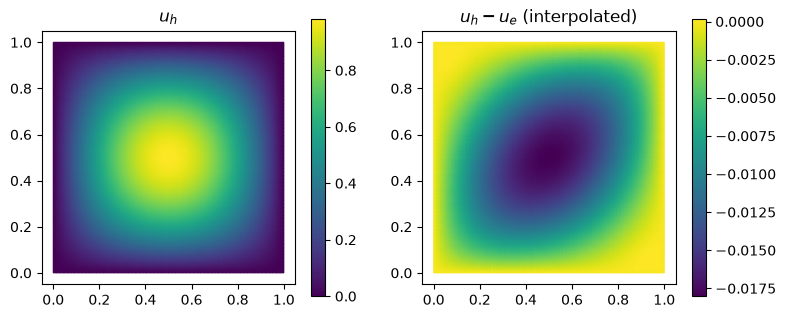

In [2]:
import matplotlib.pyplot as plt
from ngsufl.pyplot import tripcolor

err = Function(uh.function_space()).interpolate(uh - u_e)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
fig.colorbar(tripcolor(uh, axes=axs[0]), ax=axs[0])
axs[0].set_title("$u_h$")
fig.colorbar(tripcolor(err, axes=axs[1]), ax=axs[1])
axs[1].set_title("$u_h - u_e$ (interpolated)")
for ax in axs:
    ax.set_aspect("equal")

## Convergence and the penalty parameter

With quadratic elements the $L^2$ error is expected to converge with order 2.  The
penalty $\alpha$ must be large enough for coercivity.  Increasing it beyond what is needed
does not break the method but makes the discretisation stiffer, so the error grows
(the constant, not the rate).

In [3]:
def rates(errs, hs):
    return [np.log(errs[i] / errs[i + 1]) / np.log(hs[i] / hs[i + 1]) for i in range(len(errs) - 1)]

ns = [4, 8, 16, 32]
hs = [1 / n for n in ns]
errs = [errornorm(ue, uh) for _, ue, uh in (solve_biharmonic(n) for n in ns)]
print("L2 errors:", " ".join(f"{e:.2e}" for e in errs))
print("rates    :", " ".join(f"{r:.2f}" for r in rates(errs, hs)))

print("\nalpha dependence (n=16):")
for alpha in [4, 8, 16, 64]:
    _, ue, uh = solve_biharmonic(16, alpha)
    print(f"  alpha={alpha:3d}  L2 error {errornorm(ue, uh):.3e}")

L2 errors: 9.78e-02 3.27e-02 9.12e-03 2.36e-03
rates    : 1.58 1.84 1.95

alpha dependence (n=16):
  alpha=  4  L2 error 7.113e-03
  alpha=  8  L2 error 9.118e-03
  alpha= 16  L2 error 1.419e-02
  alpha= 64  L2 error 4.100e-02


The same code works for higher degree.  With $P_3$ and $\alpha=16$ the rate rises to 4 in
$L^2$ (the exact solution is smooth).

In [4]:
errs3 = [errornorm(ue, uh) for _, ue, uh in (solve_biharmonic(n, 16.0, 3) for n in [4, 8, 16])]
print("P3 L2 errors:", " ".join(f"{e:.2e}" for e in errs3))
print("P3 rates    :", " ".join(f"{r:.2f}" for r in rates(errs3, hs[:3])))

P3 L2 errors: 2.61e-03 1.76e-04 1.11e-05
P3 rates    : 3.89 3.98
